In [34]:
import pandas as pd
from pathlib import Path
import joblib

CURRENT_DIR = Path.cwd()
data = CURRENT_DIR.parent/"Data"/"encoded_sms_spam_dataset.csv"

df=pd.read_csv(data)
df.head()

,label,message
0,0,"go until jurong point, crazy.. available only ..."
1,0,ok lar... joking wif u oni...
2,1,free entry in 2 a wkly comp to win fa cup fina...
3,0,u dun say so early hor... u c already then say...
4,0,"nah i don't think he goes to usf, he lives aro..."


In [7]:
x = df['message']
y = df['label']

In [8]:
#Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
from sklearn.feature_extraction.text import TfidfVectorizer

In [29]:
#Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),  # Use unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    sublinear_tf=True
)
x_train_tfidf = vectorizer.fit_transform(x_train)
x_test_tfidf = vectorizer.transform(x_test)

In [30]:
#Train a Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(x_train_tfidf, y_train)
predictions = model.predict(x_test_tfidf)


In [31]:
#Evaluating the model
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
report = classification_report(y_test, predictions)


In [32]:
print("MODEL PERFORMANCE METRICS")
print("--------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

#The model achieves 96.42% accuracy and 96.08% precision, but its 74.81% recall indicates that it still misses a meaningful portion of actual spam messages.

MODEL PERFORMANCE METRICS
--------------------------
Accuracy: 0.9768
Precision: 0.9023
Recall: 0.9160
F1 Score: 0.9091


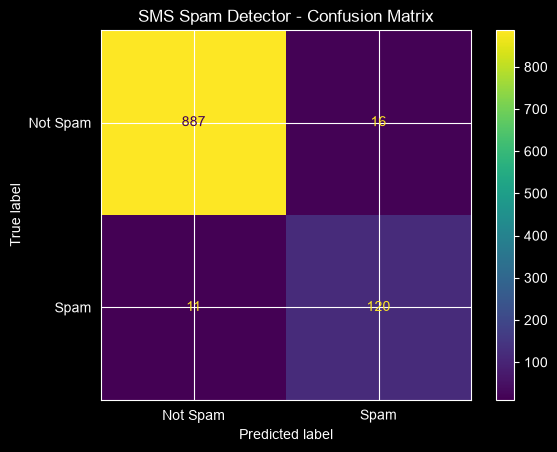

In [28]:
ConfusionMatrixDisplay.from_predictions(y_test,predictions, display_labels=['Not Spam','Spam'])
plt.title("SMS Spam Detector - Confusion Matrix")
plt.show()

In [36]:
#Saving the model and vectorizer
joblib.dump(model, CURRENT_DIR.parent/'Artifacts'/'Logistic_Regression_SMS_Spam.joblib')
joblib.dump(vectorizer, CURRENT_DIR.parent/'Artifacts'/'TfidfVectorizer_SMS_Spam.joblib')

['C:\\Users\\nelly\\Documents\\Code\\Python\\Personal Projects\\Data Science\\SMS Spam Detector\\Artifacts\\TfidfVectorizer_SMS_Spam.joblib']